# P17B — Transfer learning dan ketahanan terhadap kondisi foto
Notebook ini memakai citra retak sintesis dari Bab 16 (`praktikum/bab16/citra_retak_sintetis.npz`, buat dengan P16A) dan membandingkan empat strategi pada tiga ukuran data latih: CNN kecil dari nol, ResNet-18 pralatih ImageNet dengan fitur dibekukan dan regresi logistik, ResNet-18 pralatih yang disetel halus, dan ResNet-18 tanpa pralatihan. Bagian kedua menguji ketahanan CNN kecil terhadap penurunan kontras, derau, dan blur, dengan dan tanpa augmentasi.

**Kebutuhan.** PyTorch dan torchvision versi CPU. Bobot ResNet-18 diunduh sekali dari `download.pytorch.org` (sekitar 45 MB) saat sel pertama yang memuatnya dijalankan. Waktu jalan total sekitar 5–8 menit di CPU. Seluruh data sintesis (seed 17018); angka tidak mewakili kinerja pada foto nyata.


In [ ]:
# Folder kerja: jalankan dari folder mana pun. Sel ini pindah ke akar repositori agar jalur data relatif (praktikum/...) benar.
import os
from pathlib import Path
_akar = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "praktikum").is_dir() and (p / "notebooks").is_dir()), None)
if _akar is not None:
    os.chdir(_akar)
else:
    print("Akar repositori tidak ditemukan. Buka notebook dari dalam folder repositori hasil clone.")

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score
from scipy.ndimage import gaussian_filter

SEED = 17018
torch.set_num_threads(2)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)

def cari(nama):
    for p in (Path(nama), Path(nama).name):
        if Path(p).exists(): return Path(p)
    raise FileNotFoundError(f"{nama} tidak ditemukan; jalankan dari akar repositori (data dibuat oleh P16A).")

PyTorch 2.15.0+cpu | torchvision 0.29.2+cpu


## 1. Data dan pembagian menurut panel


In [2]:
d = np.load(cari("praktikum/bab16/citra_retak_sintetis.npz")); X, y, panel = d["X"], d["y"], d["panel"]
gs = GroupShuffleSplit(1, test_size=0.2, random_state=SEED); tmp, te = next(gs.split(X, y, panel))
gs2 = GroupShuffleSplit(1, test_size=0.25, random_state=SEED); a, b = next(gs2.split(X[tmp], y[tmp], panel[tmp])); tr, va = tmp[a], tmp[b]
print("latih/validasi/uji:", len(tr), len(va), len(te), "| panel:", len(set(panel[tr])), len(set(panel[va])), len(set(panel[te])))

latih/validasi/uji: 1440 480 480 | panel: 36 12 12


## 2. Model


In [3]:
def ke_x(Xn, ukuran=64):
    t = torch.tensor(Xn.astype(np.float32) / 255).unsqueeze(1)
    return F.interpolate(t, size=ukuran, mode="bilinear", align_corners=False)
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def untuk_resnet(t): return (t.repeat(1, 3, 1, 1) - MEAN) / STD

class CNNKecil(nn.Module):                      # sama dengan Bab 16, masukan 32 x 32
    def __init__(s):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(1024, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(s, x): return s.f(x).squeeze(1)
def resnet(pralatih):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pralatih else None)
    m.fc = nn.Linear(512, 1); return m
class Bungkus(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return s.m(untuk_resnet(x)).squeeze(1)
print("parameter CNN kecil:", sum(p.numel() for p in CNNKecil().parameters()), "| ResNet-18:", sum(p.numel() for p in resnet(False).parameters()))

parameter CNN kecil: 34081 | ResNet-18: 11177025


## 3. Fungsi pelatihan
Semua model dilatih dengan Adam, galat entropi silang biner, dan early stopping pada data validasi.


In [4]:
def latih(model, Xt, yt, Xv, yv, lr, max_epoch=25, sabar=5, batch=64, seed=0, params=None, aug=None):
    torch.manual_seed(seed); opt = torch.optim.Adam(params if params is not None else model.parameters(), lr); lf = nn.BCEWithLogitsLoss()
    yt_t, yv_t = torch.tensor(yt, dtype=torch.float32), torch.tensor(yv, dtype=torch.float32); tb, sv, sb = 1e9, None, 0
    for ep in range(max_epoch):
        model.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(perm), batch):
            bi = perm[i:i + batch]; xb = Xt[bi] if aug is None else aug(Xt[bi])
            opt.zero_grad(); lf(model(xb), yt_t[bi]).backward(); opt.step()
        model.eval()
        with torch.no_grad(): lv = lf(torch.cat([model(Xv[i:i + 256]) for i in range(0, len(Xv), 256)]), yv_t).item()
        if lv < tb - 1e-4: tb, sv, sb = lv, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            sb += 1
            if sb >= sabar: break
    model.load_state_dict(sv); model.eval(); return model, ep + 1
def prediksi(model, Xn):
    with torch.no_grad(): return (torch.cat([model(Xn[i:i + 256]) for i in range(0, len(Xn), 256)]) > 0).numpy().astype(int)
def metrik(yt, yp): return dict(akurasi=accuracy_score(yt, yp), recall=recall_score(yt, yp), presisi=precision_score(yt, yp, zero_division=0))

X32, X64 = ke_x(X, 32), ke_x(X, 64)

## 4. Empat strategi pada tiga ukuran data latih
Citra 32 × 32 diperbesar menjadi 64 × 64 dan diulang ke tiga kanal untuk ResNet. Pembagian latih/validasi/uji sama untuk semua model.


In [5]:
import pandas as pd
def satu_kali(n, sub, nama, seed):
    if nama == "CNN kecil dari nol":
        m, _ = latih(CNNKecil(), (X32[sub] - 0.5) / 0.25, y[sub], (X32[va] - 0.5) / 0.25, y[va], 3e-3, max_epoch=40, sabar=6, seed=seed); return metrik(y[te], prediksi(m, (X32[te] - 0.5) / 0.25))
    if nama == "ResNet-18 pralatih, fitur beku + regresi logistik":
        enc = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1); enc.fc = nn.Identity(); enc.eval()
        def emb(idx):
            with torch.no_grad(): return torch.cat([enc(untuk_resnet(X64[idx][i:i + 128])) for i in range(0, len(idx), 128)]).numpy()
        lr_ = LogisticRegression(max_iter=2000, C=0.5).fit(emb(sub), y[sub]); return metrik(y[te], lr_.predict(emb(te)))
    if nama == "ResNet-18 pralatih, setel halus":
        m, _ = latih(Bungkus(resnet(True)), X64[sub], y[sub], X64[va], y[va], 3e-4, max_epoch=12, sabar=3, seed=seed); return metrik(y[te], prediksi(m, X64[te]))
    m, _ = latih(Bungkus(resnet(False)), X64[sub], y[sub], X64[va], y[va], 1e-3, max_epoch=12, sabar=3, seed=seed); return metrik(y[te], prediksi(m, X64[te]))
NAMA = ["CNN kecil dari nol", "ResNet-18 pralatih, fitur beku + regresi logistik", "ResNet-18 pralatih, setel halus", "ResNet-18 dari nol"]
baris = []
for n in (60, 240, 1000):
    sub = np.random.default_rng(SEED + n).choice(tr, size=min(n, len(tr)), replace=False)
    seeds = (1, 2, 3) if n < 1000 else (1,)          # n = 1000 hanya satu benih (waktu)
    t0 = time.perf_counter()
    for nama in NAMA:
        hs = [satu_kali(n, sub, nama, sd) for sd in seeds]
        baris.append({"n_latih": n, "model": nama, "benih": len(seeds), "akurasi": np.mean([h["akurasi"] for h in hs]), "sd_akurasi": np.std([h["akurasi"] for h in hs], ddof=1) if len(hs) > 1 else np.nan,
                      "recall": np.mean([h["recall"] for h in hs]), "presisi": np.mean([h["presisi"] for h in hs])})
    print("selesai n =", n, "%.0f detik" % (time.perf_counter() - t0))
tab = pd.DataFrame(baris).round(3); print(tab.to_string(index=False))
print("Catatan: menebak 'retak' untuk semua citra uji memberi akurasi", round(float(y[te].mean()), 3), "dan recall 1,0.")

selesai n = 60 69 detik


selesai n = 240 119 detik


selesai n = 1000 116 detik
 n_latih                                             model  benih  akurasi  sd_akurasi  recall  presisi
      60                                CNN kecil dari nol      3    0.540       0.000   1.000    0.540
      60 ResNet-18 pralatih, fitur beku + regresi logistik      3    0.860       0.000   0.888    0.858
      60                   ResNet-18 pralatih, setel halus      3    0.809       0.023   0.775    0.871
      60                                ResNet-18 dari nol      3    0.508       0.019   0.296    0.772
     240                                CNN kecil dari nol      3    0.828       0.022   0.740    0.927
     240 ResNet-18 pralatih, fitur beku + regresi logistik      3    0.915       0.000   0.900    0.940
     240                   ResNet-18 pralatih, setel halus      3    0.906       0.026   0.879    0.943
     240                                ResNet-18 dari nol      3    0.544       0.046   0.534    0.716
    1000                             

## 5. Ketahanan terhadap kondisi foto
Gangguan diterapkan hanya pada citra uji: kontras dikurangi terhadap rerata citra, derau Gaussian ditambahkan, atau citra dikaburkan. CNN kecil dilatih tanpa augmentasi dan dengan augmentasi (balik, variasi kontras dan kecerahan, derau).


In [6]:
def kontras(Xn, f): return np.clip((Xn.astype(float) - Xn.mean(axis=(1, 2), keepdims=True)) * f + Xn.mean(axis=(1, 2), keepdims=True), 0, 255).astype(np.uint8)
def derau(Xn, s, r): return np.clip(Xn + r.normal(0, s, Xn.shape), 0, 255).astype(np.uint8)
def kabur(Xn, s): return np.stack([gaussian_filter(x.astype(float), s) for x in Xn]).astype(np.uint8)
def tes_ketahanan(prd, nama, Xtest):
    r = np.random.default_rng(SEED + 5)
    kasus = {"asli": Xtest, "kontras 0,6": kontras(Xtest, 0.6), "kontras 0,4": kontras(Xtest, 0.4), "derau σ = 10": derau(Xtest, 10, r), "derau σ = 25": derau(Xtest, 25, r), "kabur σ = 1,0": kabur(Xtest, 1.0), "kabur σ = 2,0": kabur(Xtest, 2.0)}
    return {k: metrik(y[te], prd(v)) for k, v in kasus.items()}

In [7]:
def aug_bat(xb):                                           # xb: (b,1,32,32) sudah dinormalisasi
    xb = xb.clone()
    if torch.rand(1) < 0.5: xb = xb.flip(3)
    if torch.rand(1) < 0.5: xb = xb.flip(2)
    k = torch.empty(len(xb), 1, 1, 1).uniform_(0.4, 1.2); xb = xb * k + torch.randn(len(xb), 1, 1, 1) * 0.2
    xb = xb + torch.randn_like(xb) * torch.empty(len(xb), 1, 1, 1).uniform_(0, 0.8)
    return xb
Xtr32, Xva32 = (X32[tr] - 0.5) / 0.25, (X32[va] - 0.5) / 0.25
m_pol, _ = latih(CNNKecil(), Xtr32, y[tr], Xva32, y[va], 3e-3, max_epoch=40, sabar=6, seed=1)
m_aug, ep_aug = latih(CNNKecil(), Xtr32, y[tr], Xva32, y[va], 3e-3, max_epoch=60, sabar=8, seed=1, aug=aug_bat)
def prd32(m): return lambda Xn: prediksi(m, (ke_x(Xn, 32) - 0.5) / 0.25)
r1, r2 = tes_ketahanan(prd32(m_pol), "polos", X[te]), tes_ketahanan(prd32(m_aug), "augmentasi", X[te])
tab2 = pd.DataFrame({"kondisi": list(r1), "akurasi polos": [v["akurasi"] for v in r1.values()], "recall polos": [v["recall"] for v in r1.values()],
                     "akurasi augmentasi": [v["akurasi"] for v in r2.values()], "recall augmentasi": [v["recall"] for v in r2.values()]}).round(3); print(tab2.to_string(index=False))

      kondisi  akurasi polos  recall polos  akurasi augmentasi  recall augmentasi
         asli          0.944         0.931               0.788              0.822
  kontras 0,6          0.546         0.158               0.744              0.571
  kontras 0,4          0.460         0.000               0.615              0.286
 derau σ = 10          0.540         1.000               0.794              0.784
 derau σ = 25          0.540         1.000               0.775              0.707
kabur σ = 1,0          0.535         0.139               0.798              0.768
kabur σ = 2,0          0.462         0.004               0.762              0.591


## 6. Gambar


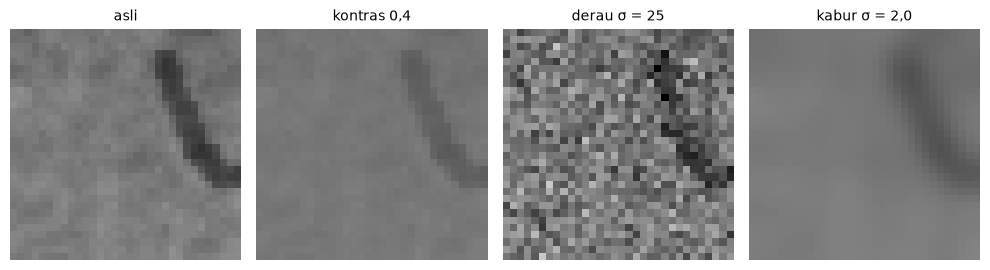

In [8]:
r = np.random.default_rng(SEED + 9); idx = te[np.where(y[te] == 1)[0][:1]]
var = {"asli": X[idx], "kontras 0,4": kontras(X[idx], 0.4), "derau σ = 25": derau(X[idx], 25, r), "kabur σ = 2,0": kabur(X[idx], 2.0)}
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
for a_, (k, v) in zip(ax, var.items()): a_.imshow(v[0], cmap="gray", vmin=0, vmax=255); a_.set_title(k, fontsize=10); a_.axis("off")
plt.tight_layout(); plt.show()

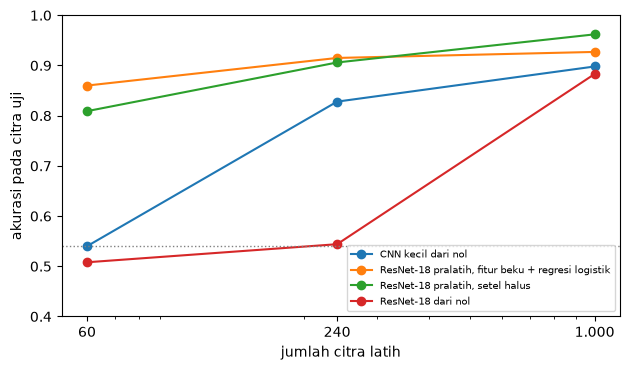

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for nm in ["CNN kecil dari nol", "ResNet-18 pralatih, fitur beku + regresi logistik", "ResNet-18 pralatih, setel halus", "ResNet-18 dari nol"]:
    ax.plot([60, 240, 1000], [tab[(tab.n_latih == n) & (tab.model == nm)].akurasi.iloc[0] for n in (60, 240, 1000)], "o-", label=nm)
ax.set_xscale("log"); ax.set_xticks([60, 240, 1000]); ax.set_xticklabels(["60", "240", "1.000"]); ax.set_xlabel("jumlah citra latih"); ax.set_ylabel("akurasi pada citra uji"); ax.axhline(float(y[te].mean()), color="gray", ls=":", lw=1); ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=7.5, loc="lower right"); plt.tight_layout(); plt.show()

**Catatan batas.** Satu benih dan satu pembagian panel; selisih kecil antarmodel (misalnya 0,915 dan 0,927) tidak boleh dibaca sebagai keunggulan. Model pralatih dilatih pada foto alam; hasilnya pada citra sintesis tidak menjamin hasil pada foto retak nyata.
